# Projected time evolution (ptVMC)

This notebook shows how to simulate unitary dynamics, $|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle$, with projected time-dependent VMC (ptVMC). The TDVP example integrates an equation of motion for the network parameters. ptVMC instead turns every time step into an optimisation: given the state $|\psi_{\theta_n}\rangle$ at time $t_n$, the state at $t_{n+1} = t_n + \tau$ is the one closest to the propagated state,

$$
\theta_{n+1} = \operatorname*{arg\,min}_\theta \; \mathcal I\big(\psi_\theta,\; \hat U(\tau)\,\psi_{\theta_n}\big),
\qquad
\mathcal I(\psi, \hat O\chi) = 1 - \frac{|\langle\psi|\hat O|\chi\rangle|^2}{\langle\psi|\psi\rangle\,\langle\chi|\hat O^\dagger\hat O|\chi\rangle},
$$

where $\hat U(\tau)\approx e^{-iH\tau}$. Each minimisation is an infidelity optimisation, as in the infidelity optimisation example, with `jVMC.objective_function.Infidelity`. Its reference state $|\chi\rangle$ is a copy of the variational state at the previous time, and its operator is (a factor of) the short-time propagator. The infidelity left after each fit measures the error of that step, and this local error control is the main appeal of ptVMC. The cost is an optimisation at every step, instead of a single linear solve. We follow the scheme of L. Gravina, V. Savona and F. Vicentini, *Neural projected quantum dynamics: a systematic study*, Quantum **9**, 1803 (2025).

We use the same system as the TDVP example: an Ising chain in a transverse and a longitudinal field, with periodic boundary conditions,

$$
H = -\sum_{l} \sigma^z_l \sigma^z_{l+1} + g \sum_{l} \sigma^x_l + h \sum_{l} \sigma^z_l ,
$$

with the same network and initial state, so the two methods can be compared directly.

The example is structured as follows:

1. Set up the Hamiltonian, the variational state $|\psi_\theta\rangle$ and the reference state $|\chi\rangle$.
2. Build the short-time propagator as a product of operators that are linear in $H$.
3. Set up the optimizer that performs each fit.
4. Run the ptVMC time evolution.
5. Compare with the exact evolution.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import tqdm

import jVMC
import jVMC.operator.discrete as op

Running in single-node mode (JVMC_USE_DISTRIBUTED not set)


## 1. Hamiltonian, states and samplers

ptVMC needs two states with the same network:

- `psi`, the variational state $|\psi_\theta\rangle$ that is optimised;
- `chi`, the reference state $|\chi\rangle$, which holds a copy of the parameters of `psi` from the beginning of the current fit and stays fixed during it.

As in the TDVP example, the initial state is the network at its random initialisation, with the same seed. The system is small ($2^6 = 64$ configurations), so both states use an `ExactSampler`. This isolates the errors of ptVMC from the sampling noise; see the end of the notebook for Monte Carlo sampling.

In [2]:
L = 6
g = -0.7
h = 0.1

tau = 0.05  # time step
t_max = 2.0

# Hamiltonian and transverse magnetization
hamiltonian = 0
M_x = 0
for l in range(L):
    hamiltonian += -1 * op.SigmaZ(l) * op.SigmaZ((l + 1) % L) + g * op.SigmaX(l) + h * op.SigmaZ(l)
    M_x += op.SigmaX(l)
M_x /= L

# Variational state psi and reference state chi, with the same network
net = jVMC.nets.CpxRBM(num_hidden=10, bias=True)
psi = jVMC.vqs.NQS(net, sample_shape=L, batch_size=2**L, seed=123)
chi = jVMC.vqs.NQS(net, sample_shape=L, batch_size=2**L)
chi.parameters = psi.parameters

psi_sampler = jVMC.sampler.ExactSampler(psi)
chi_sampler = jVMC.sampler.ExactSampler(chi)

print("Number of parameters: ", psi.num_parameters)

Number of parameters:  70


## 2. The short-time propagator

`Infidelity` applies an operator $\hat O$ to the reference state, and its cost grows with the number of configurations that $\hat O$ connects. The exact propagator $e^{-iH\tau}$ connects all of them, so we approximate it by its Taylor expansion of order $o$ and write that as a product of $o$ factors linear in $H$:

$$
e^{-iH\tau} = \sum_{k=0}^{o}\frac{(-iH\tau)^k}{k!} + \mathcal O(\tau^{o+1})
= \prod_{k=1}^{o}\big(1 - i a_k \tau H\big) + \mathcal O(\tau^{o+1}),
\qquad a_k = -\frac{1}{z_k},
$$

where $z_k$ are the (complex) roots of the polynomial $\sum_{k=0}^{o} z^k/k!$. Gravina et al. call this a product expansion. Each factor $\hat O_k = 1 - i a_k\tau H$ connects only as many configurations as $H$ itself. The factors are applied one after the other, so a time step consists of $o$ fits, each targeting $\hat O_k|\psi_{\theta}\rangle$ for the current $\theta$. We use $o = 4$, which has the same order as the RK4 integrator.

`Infidelity` needs both $\hat O_k$ and its adjoint $\hat O_k^\dagger = 1 + i a_k^* \tau H$. The cell below also checks the expansion against the exact propagator, using dense matrices that `to_dense()` builds on the basis of the `ExactSampler`.

In [3]:
order = 4

# a_k = -1 / z_k, with z_k the roots of sum_k z^k / k!
roots = np.roots([1 / math.factorial(k) for k in range(order, -1, -1)])
coefficients = -1 / roots
print("a_k =", np.round(coefficients, 4))

identity = op.IdentityOperator(2, 0)
factors = [
    (identity - 1j * a * tau * hamiltonian, identity + 1j * np.conj(a) * tau * hamiltonian)
    for a in coefficients
]

# Check with dense matrices that the product of the factors approximates exp(-i H tau)
basis = psi_sampler.basis
H_dense = np.asarray(hamiltonian.to_dense(basis))
M_x_dense = np.asarray(M_x.to_dense(basis))
eigenvalues, eigenvectors = np.linalg.eigh(H_dense)


def exact_propagator(t):
    return eigenvectors @ np.diag(np.exp(-1j * eigenvalues * t)) @ eigenvectors.conj().T


product = np.eye(2**L, dtype=complex)
for operator, _ in factors:
    product = np.asarray(operator.to_dense(basis)) @ product

print(f"||prod_k O_k - exp(-iH tau)||  = {np.linalg.norm(product - exact_propagator(tau), 2):.2e}")
print(f"(||H|| tau)^(o+1) / (o+1)!     = {(np.abs(eigenvalues).max() * tau) ** (order + 1) / math.factorial(order + 1):.2e}")

a_k = [0.0426+0.3946j 0.0426-0.3946j 0.4574+0.2351j 0.4574-0.2351j]
||prod_k O_k - exp(-iH tau)||  = 5.46e-05
(||H|| tau)^(o+1) / (o+1)!     = 5.46e-05


For every factor we create an `Infidelity` with the reference sampler `chi_sampler`. Since `chi_sampler` samples `chi`, updating `chi.parameters` is enough to move the reference state forward in time: the objective functions do not have to be rebuilt.

The factors are not unitary. `Infidelity` divides by $\langle\chi|\chi\rangle$ but not by $\langle\chi|\hat O_k^\dagger\hat O_k|\chi\rangle$, so its value is $1 - N_k F$, with $F$ the fidelity and $N_k = \langle\chi|\hat O_k^\dagger\hat O_k|\chi\rangle/\langle\chi|\chi\rangle = 1 + \mathcal O(\tau)$. The minimum is the same, and the gradient is only rescaled by $N_k$, which does not depend on $\theta$. To report the infidelity itself, we measure $N_k$ with the reference sampler and use $\mathcal I = 1 - (1 - \mathcal I_{\rm estimator})/N_k$.

In [4]:
losses = [
    jVMC.objective_function.Infidelity(chi_sampler, operator, conjugated_operator)
    for operator, conjugated_operator in factors
]
# O_k^dagger O_k, to normalise the infidelity
norm_operators = [conjugated_operator * operator for operator, conjugated_operator in factors]

## 3. The optimizer for the fits

Each fit is a short minimisation with stochastic reconfiguration, as in the infidelity optimisation example. It starts from the current state, which is already close to its target since $\hat O_k = 1 + \mathcal O(\tau)$, so a few steps are enough. A learning rate of $0.5$ converges reliably here; larger rates can overshoot and lose the state.

Instead of `ground_state_search()`, which shows a progress bar and records the loss at every call, the fit calls `opt.step()` directly. It returns the new parameters, which are then set on `psi`. At the end of a fit the infidelity is evaluated once more on the final parameters and normalised by $N_k$.

In [5]:
num_fit_steps = 20
learning_rate = 0.5

opt = jVMC.optimizer.SR(psi_sampler, psi, diagonal_shift=1e-4)
stepper = jVMC.stepper.Euler(learning_rate)


def fit(loss, norm_operator):
    # The target of this fit is O_k applied to the current state
    chi.parameters = psi.parameters

    for _ in range(num_fit_steps):
        new_parameters, _ = opt.step(0, stepper, loss)
        psi.parameters = new_parameters

    # Infidelity at the final parameters, normalised by N_k = <chi|O_k^dagger O_k|chi>
    psi_sampler.sample()
    infidelity = loss(psi_sampler).mean.real.item()
    norm = chi_sampler(norm_operator).mean.real.item()
    return 1 - (1 - infidelity) / norm

## 4. Run the time evolution

Every time step applies the $o$ factors one after the other, each with one fit. After each step we measure the energy and the transverse magnetization $M_x = \frac{1}{L}\sum_l\sigma^x_l$ with `psi_sampler`, and record the infidelities of the fits. We also store the full state vector with `psi.to_array(basis)`, which is only possible for small systems, to compare with the exact evolution below.

In [6]:
num_steps = int(round(t_max / tau))
times = tau * np.arange(num_steps + 1)


def measure():
    psi_sampler.sample()
    energy = psi_sampler(hamiltonian).mean.real.item()
    magnetization = psi_sampler(M_x).mean.real.item()
    return energy, magnetization, np.asarray(psi.to_array(basis))


energy, magnetization, states = map(list, zip(measure()))
fit_infidelity = np.zeros((num_steps, order))

for n in tqdm.trange(num_steps):
    for k, (loss, norm_operator) in enumerate(zip(losses, norm_operators)):
        fit_infidelity[n, k] = fit(loss, norm_operator)

    e, m, state = measure()
    energy.append(e)
    magnetization.append(m)
    states.append(state)

energy = np.array(energy)
magnetization = np.array(magnetization)

100%|██████████| 40/40 [01:18<00:00,  1.96s/it]


## 5. Comparison with the exact evolution

The exact state $e^{-iHt}|\psi(0)\rangle$ follows from the dense Hamiltonian. We compare:

- the **energy**, which unitary evolution conserves, so any drift is an error of the simulation;
- the **transverse magnetization**, with its exact value;
- the **infidelity with the exact state**, $1 - |\langle\psi_{\rm exact}(t)|\psi_\theta(t)\rangle|^2$ for normalised states, which collects all errors up to time $t$;
- the **infidelity of the fits**, summed over the $o$ fits of each step, i.e. the error added by the optimisation at every step.

The infidelity with the exact state collects two errors: the residual infidelity of the fits, and the truncation of the propagator at order $o$. Here the truncation error is negligible. The infidelity with the exact state grows while the fits leave a residual of about $10^{-7}$, and stays flat once the fits become essentially exact, after $t\approx 1$. The truncation error matters for a lower order or a larger time step: with $o = 2$ and the same $\tau$, the infidelity with the exact state already reaches about $10^{-3}$ at $t = 0.5$.

Largest deviation of the energy:         1.94e-04
Largest deviation of the magnetization:  8.84e-05
Infidelity with the exact state at t_max: 1.37e-05


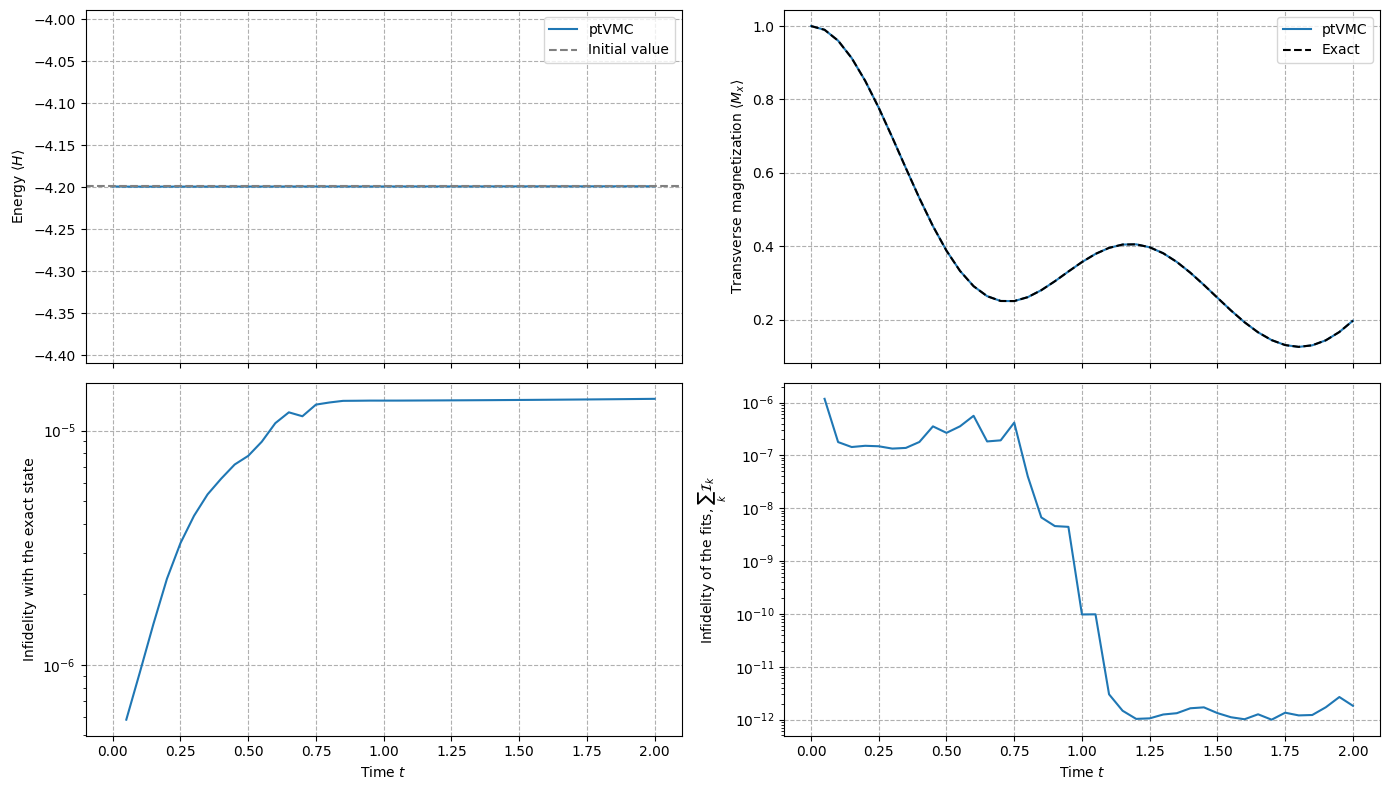

In [7]:
exact_states = [exact_propagator(t) @ states[0] for t in times]
exact_magnetization = np.array([np.real(np.vdot(v, M_x_dense @ v)) for v in exact_states])
exact_infidelity = np.array([1 - np.abs(np.vdot(v, s)) ** 2 for v, s in zip(exact_states, states)])

fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

ax = axs[0, 0]
ax.plot(times, energy, label="ptVMC")
ax.axhline(energy[0], ls="--", color="gray", label="Initial value")
ax.set_ylim(energy[0] - 0.05 * abs(energy[0]), energy[0] + 0.05 * abs(energy[0]))
ax.set_ylabel(r"Energy $\langle H\rangle$")
ax.legend()

ax = axs[0, 1]
ax.plot(times, magnetization, label="ptVMC")
ax.plot(times, exact_magnetization, "--", color="black", label="Exact")
ax.set_ylabel(r"Transverse magnetization $\langle M_x\rangle$")
ax.legend()

ax = axs[1, 0]
ax.plot(times[1:], exact_infidelity[1:])
ax.set_yscale("log")
ax.set_ylabel(r"Infidelity with the exact state")

ax = axs[1, 1]
ax.plot(times[1:], fit_infidelity.sum(axis=1))
ax.set_yscale("log")
ax.set_ylabel(r"Infidelity of the fits, $\sum_k \mathcal{I}_k$")

for ax in axs.flat:
    ax.grid(ls="--")
for ax in axs[1]:
    ax.set_xlabel(r"Time $t$")

plt.tight_layout()

print(f"Largest deviation of the energy:         {np.abs(energy - energy[0]).max():.2e}")
print(f"Largest deviation of the magnetization:  {np.abs(magnetization - exact_magnetization).max():.2e}")
print(f"Infidelity with the exact state at t_max: {exact_infidelity[-1]:.2e}")

## Going further

- **Monte Carlo sampling.** For larger systems, replace both `ExactSampler`s with `MCSampler`s, with independent seeds for `psi` and `chi`, as in the infidelity optimisation example. The infidelity is then a product of two noisy estimates, and its variance can be reduced with `control_variate="adaptive"` in `Infidelity`. The control variate leaves the gradient unchanged, but its correction to the value has zero mean only for a unitary operator, so with the non-unitary factors used here the reported value is biased. More fit steps, or a stopping criterion on the infidelity, are usually needed as well.
- **Other propagators.** Any operator can be used in `Infidelity`. Instead of the product expansion, the propagator can be split into a Trotter product of two-site gates $e^{-ih_{l,l+1}\tau}$, each built from its dense $4\times4$ matrix with `jVMC.util.util.matrix_to_jvmc_operator(matrix, sites, return_conjugate=True)` and fitted in turn.